In [11]:
import pandas as pd
calls_df = pd.read_csv("119call.csv", encoding='cp949') # pandas를 pd라는 이름으로 불러옵니다. 
#"119call.csv" 파일을 cp949 인코딩으로 읽어와 calls_df에 저장합니다

daily_calls = calls_df.groupby('날짜')['신고건수'].sum().reset_index()# '날짜' 컬럼을 기준으로 그룹화하여 신고건수를 일자별로 합산,
#reset_index()를 통해 그룹화 결과를 다시 일반적인 DataFrame 형식

daily_calls['날짜'] = pd.to_datetime(daily_calls['날짜'].astype(str), format='%Y%m%d')#문자열 형식인 '날짜'를 datetime 객체로 변환

weather_files = ['20년_부산_기상청자료.csv', '21년_부산_기상청자료.csv', '22년_부산_기상청자료.csv', '23년_부산_기상청자료.csv']
#2020년부터 2023년까지의 기상 데이터 파일명을 리스트로 저장
weather_dfs = [pd.read_csv(f, encoding='cp949') for f in weather_files]
# 리스트의 파일들을 하나씩 읽어와서 weather_dfs라는 리스트에 저장
weather_df = pd.concat(weather_dfs, ignore_index=True)
# 연도별 기상 데이터를 하나의 DataFrame으로 합침

# 일시 → 날짜로 변경, 일시' 컬럼을 datetime 형식으로 변환
weather_df['일시'] = pd.to_datetime(weather_df['일시'])

# 두 데이터 병합을 위해 '일시'라는 컬럼명을 '날짜'로 바꿈, 두 날짜 형식을 XXXX-XX-XX 으로 맞춰줌
weather_df.rename(columns={'일시': '날짜'}, inplace=True)
weather_df['날짜'] = pd.to_datetime(weather_df['날짜'], format='%Y-%m-%d')

# 일자 기준으로 두 DataFrame을 내부 조인(inner join)
merged_df = pd.merge(daily_calls, weather_df, on='날짜', how='inner')
merged_df.fillna(0, inplace=True)


In [12]:
#병합된 데이터 확인
print(merged_df.head())

          날짜  신고건수   지점 지점명  평균기온(°C)  최저기온(°C)  최고기온(°C)  일강수량(mm)  \
0 2020-05-01    89  159  부산      19.5      16.7      22.7       0.0   
1 2020-05-02    81  159  부산      18.7      17.0      21.8       1.1   
2 2020-05-03    74  159  부산      16.8      16.2      17.9      21.3   
3 2020-05-04    97  159  부산      19.0      15.8      25.0       0.0   
4 2020-05-05    70  159  부산      15.9      14.2      18.5       0.0   

   최대 순간 풍속(m/s)  최대 풍속(m/s)  평균 이슬점온도(°C)  최소 상대습도(%)  
0           14.4         9.4          15.2        64.0  
1           10.0         6.5          15.7        69.0  
2            9.3         5.0          15.9        89.0  
3            9.1         6.8          16.2        63.0  
4            8.3         4.2          12.3        68.0  


In [13]:
from sklearn.preprocessing import StandardScaler
import numpy as np

# 1. 분석 모델에는 불필요한 컬럼(날짜, 지점 관련)을 제거, 기상 변수들과 신고건수만 남음
data_model = merged_df.drop(columns=['날짜', '지점', '지점명'])

# 2. 스케일링 : StandardScaler는 평균을 0, 표준편차를 1로 맞추는 정규화 방법,신고건수는 예측 대상이므로 스케일링 대상에서 제외
# 모든 기상 변수들이 동일한 스케일로 변환
scaler = StandardScaler()
scaled_features = scaler.fit_transform(data_model.drop(columns=['신고건수']))

# 3. scaled_features와 신고건수 합치기
scaled_data = np.hstack([scaled_features, data_model[['신고건수']].values])

# 4. 시퀀스 생성 함수 (7일 window 예시)
# X: 지난 7일간의 기상 변수 정보
# y: 그 다음 날의 신고건수
def create_sequences(data, window_size=7):
    X, y = [], []
    for i in range(len(data) - window_size):
        X.append(data[i:i+window_size, :-1])  # 입력 특성 (기상 변수)
        y.append(data[i+window_size, -1])     # 타깃 신고건수
    return np.array(X), np.array(y)

X, y = create_sequences(scaled_data, window_size=7)

print(X.shape) #X.shape: (샘플 수, 7일, 기상 변수 개수)
print(y.shape)  # (샘플 수,) → 각 샘플에 해당하는 예측 목표값(신고건수)


(913, 7, 8)
(913,)


Epoch 1/50
46/46 - 9s - loss: 0.0078 - val_loss: 6.2664e-04 - 9s/epoch - 195ms/step
Epoch 2/50
46/46 - 2s - loss: 0.0027 - val_loss: 5.2903e-04 - 2s/epoch - 35ms/step
Epoch 3/50
46/46 - 2s - loss: 0.0023 - val_loss: 3.7118e-04 - 2s/epoch - 43ms/step
Epoch 4/50
46/46 - 3s - loss: 0.0026 - val_loss: 3.9403e-04 - 3s/epoch - 58ms/step
Epoch 5/50
46/46 - 1s - loss: 0.0022 - val_loss: 5.6980e-04 - 1s/epoch - 30ms/step
Epoch 6/50
46/46 - 2s - loss: 0.0020 - val_loss: 6.9191e-04 - 2s/epoch - 49ms/step
Epoch 7/50
46/46 - 2s - loss: 0.0021 - val_loss: 4.4068e-04 - 2s/epoch - 52ms/step
Epoch 8/50
46/46 - 2s - loss: 0.0019 - val_loss: 7.2113e-04 - 2s/epoch - 53ms/step
Epoch 9/50
46/46 - 2s - loss: 0.0019 - val_loss: 3.0464e-04 - 2s/epoch - 52ms/step
Epoch 10/50
46/46 - 2s - loss: 0.0020 - val_loss: 5.4186e-04 - 2s/epoch - 44ms/step
Epoch 11/50
46/46 - 2s - loss: 0.0019 - val_loss: 3.6298e-04 - 2s/epoch - 52ms/step
Epoch 12/50
46/46 - 2s - loss: 0.0017 - val_loss: 0.0011 - 2s/epoch - 52ms/step
Epoc

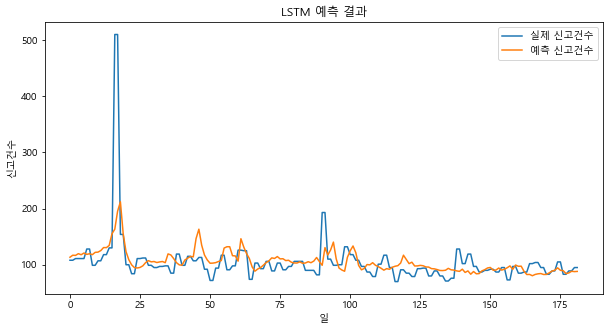

RMSE: 39.71

일별 신고건수 예측 결과 (예측 / 실제)
Day 1: 113.4 / 108.0
Day 2: 116.9 / 108.0
Day 3: 116.7 / 111.0
Day 4: 119.7 / 111.0
Day 5: 117.8 / 111.0


In [19]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import MinMaxScaler
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.metrics import mean_squared_error
from tensorflow.keras.layers import Dropout
import matplotlib.pyplot as plt


plt.rcParams['font.family'] = 'Malgun Gothic'
plt.rcParams['axes.unicode_minus'] = False

# 1. 결측치 처리
merged_df.fillna(0, inplace=True)

# 2. 특성 및 타겟 설정
features = ['평균기온(°C)', '최저기온(°C)', '최고기온(°C)', '일강수량(mm)', 
            '최대 순간 풍속(m/s)', '최대 풍속(m/s)', '평균 이슬점온도(°C)', '최소 상대습도(%)']
target = '신고건수'

# 3. 정규화
scaler_X = MinMaxScaler()
scaler_y = MinMaxScaler()

X_scaled = scaler_X.fit_transform(merged_df[features])
y_scaled = scaler_y.fit_transform(merged_df[[target]])

# 4. 시퀀스 생성 함수
def create_sequences(X, y, seq_length=14):
    X_seq, y_seq = [], []
    for i in range(len(X) - seq_length):
        X_seq.append(X[i:i+seq_length])
        y_seq.append(y[i+seq_length])
    return np.array(X_seq), np.array(y_seq)

seq_length = 14
X_seq, y_seq = create_sequences(X_scaled, y_scaled, seq_length)

# 5. 학습/테스트 분리 (80% / 20%)
split_idx = int(len(X_seq) * 0.8)
X_train, X_test = X_seq[:split_idx], X_seq[split_idx:]
y_train, y_test = y_seq[:split_idx], y_seq[split_idx:]

# 6. LSTM 모델 구성
model_lstm = Sequential([
    LSTM(164, activation='tanh', input_shape=(seq_length, X_seq.shape[2])),
    Dropout(0.2),
    Dense(1)
])
model_lstm.compile(optimizer='adam', loss='mse')

# 7. EarlyStopping 콜백 설정
early_stop = EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)

# 8. 모델 학습
history = model_lstm.fit(
    X_train, y_train,
    epochs=50,
    batch_size=16,
    validation_data=(X_test, y_test),
    callbacks=[early_stop],
    verbose=2
)

# 9. 예측 및 역정규화
y_pred_scaled = model_lstm.predict(X_test)
y_pred = scaler_y.inverse_transform(y_pred_scaled)
y_test_actual = scaler_y.inverse_transform(y_test)

# 10. 결과 시각화
plt.figure(figsize=(10,5))
plt.plot(y_test_actual, label='실제 신고건수')
plt.plot(y_pred, label='예측 신고건수')
plt.legend()
plt.title("LSTM 예측 결과")
plt.xlabel("일")
plt.ylabel("신고건수")
plt.show()

# 11. RMSE 계산 및 출력
mse = mean_squared_error(y_test_actual, y_pred)
rmse = np.sqrt(mse)
print(f"RMSE: {rmse:.2f}")

print("")
print("일별 신고건수 예측 결과 (예측 / 실제)")
for i in range(5):
    print(f"Day {i+1}: {y_pred[i][0]:.1f} / {y_test_actual[i][0]:.1f}")

Epoch 1/50
46/46 - 2s - loss: 0.0055 - val_loss: 7.1159e-04 - 2s/epoch - 48ms/step
Epoch 2/50
46/46 - 0s - loss: 0.0024 - val_loss: 8.4271e-04 - 393ms/epoch - 9ms/step
Epoch 3/50
46/46 - 0s - loss: 0.0021 - val_loss: 6.2411e-04 - 379ms/epoch - 8ms/step
Epoch 4/50
46/46 - 0s - loss: 0.0020 - val_loss: 0.0019 - 470ms/epoch - 10ms/step
Epoch 5/50
46/46 - 0s - loss: 0.0021 - val_loss: 0.0015 - 309ms/epoch - 7ms/step
Epoch 6/50
46/46 - 0s - loss: 0.0018 - val_loss: 0.0011 - 209ms/epoch - 5ms/step
Epoch 7/50
46/46 - 0s - loss: 0.0017 - val_loss: 7.3306e-04 - 251ms/epoch - 5ms/step
Epoch 8/50
46/46 - 0s - loss: 0.0020 - val_loss: 7.9494e-04 - 463ms/epoch - 10ms/step
Epoch 9/50
46/46 - 0s - loss: 0.0019 - val_loss: 5.2882e-04 - 284ms/epoch - 6ms/step
Epoch 10/50
46/46 - 0s - loss: 0.0019 - val_loss: 4.8789e-04 - 292ms/epoch - 6ms/step
Epoch 11/50
46/46 - 0s - loss: 0.0017 - val_loss: 0.0014 - 291ms/epoch - 6ms/step
Epoch 12/50
46/46 - 0s - loss: 0.0018 - val_loss: 8.0341e-04 - 283ms/epoch - 6m

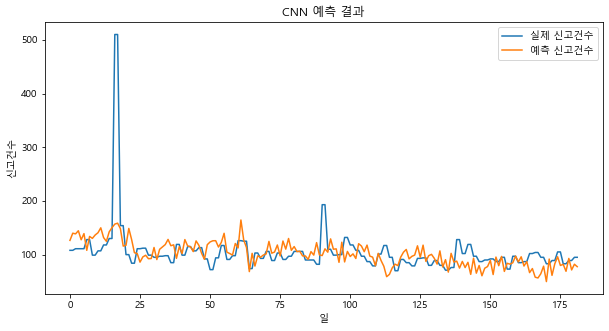

RMSE: 43.97
일별 신고건수 예측 결과 (예측 / 실제)
Day 1: 126.5 / 108.0
Day 2: 139.9 / 108.0
Day 3: 138.6 / 111.0
Day 4: 144.5 / 111.0
Day 5: 127.7 / 111.0


In [20]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import MinMaxScaler
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv1D, Dense, Flatten
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.metrics import mean_squared_error
import matplotlib.pyplot as plt

plt.rcParams['font.family'] = 'Malgun Gothic'
plt.rcParams['axes.unicode_minus'] = False

# 1. 결측치 처리 (이미 했으면 생략 가능)
merged_df.fillna(0, inplace=True)

# 2. 특성 및 타겟
features = ['평균기온(°C)', '최저기온(°C)', '최고기온(°C)', '일강수량(mm)', 
            '최대 순간 풍속(m/s)', '최대 풍속(m/s)', '평균 이슬점온도(°C)', '최소 상대습도(%)']
target = '신고건수'

# 3. 정규화
scaler_X = MinMaxScaler()
scaler_y = MinMaxScaler()

X_scaled = scaler_X.fit_transform(merged_df[features])
y_scaled = scaler_y.fit_transform(merged_df[[target]])

# 4. 시퀀스 생성 함수 (LSTM과 동일)
def create_sequences(X, y, seq_length=14):
    X_seq, y_seq = [], []
    for i in range(len(X) - seq_length):
        X_seq.append(X[i:i+seq_length])
        y_seq.append(y[i+seq_length])
    return np.array(X_seq), np.array(y_seq)

seq_length = 14
X_seq, y_seq = create_sequences(X_scaled, y_scaled, seq_length)

# 5. 학습/테스트 분리
split_idx = int(len(X_seq) * 0.8)
X_train, X_test = X_seq[:split_idx], X_seq[split_idx:]
y_train, y_test = y_seq[:split_idx], y_seq[split_idx:]

# 6. CNN 모델 구성
model_cnn = Sequential([
    Conv1D(filters=64, kernel_size=3, activation='relu', input_shape=(seq_length, X_seq.shape[2])),
    Flatten(),
    Dense(32, activation='relu'),
    Dense(1)
])
model_cnn.compile(optimizer='adam', loss='mse')

# 7. EarlyStopping 콜백 설정
early_stop = EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)

# 8. 모델 학습
history = model_cnn.fit(
    X_train, y_train,
    epochs=50,
    batch_size=16,
    validation_data=(X_test, y_test),
    callbacks=[early_stop],
    verbose=2
)

# 9. 예측 및 역정규화
y_pred_scaled = model_cnn.predict(X_test)
y_pred = scaler_y.inverse_transform(y_pred_scaled)
y_test_actual = scaler_y.inverse_transform(y_test)

# 10. 결과 시각화
plt.figure(figsize=(10,5))
plt.plot(y_test_actual, label='실제 신고건수')
plt.plot(y_pred, label='예측 신고건수')
plt.legend()
plt.title("CNN 예측 결과")
plt.xlabel("일")
plt.ylabel("신고건수")
plt.show()

# 11. RMSE 계산 및 출력
mse = mean_squared_error(y_test_actual, y_pred)
rmse = np.sqrt(mse)
print(f"RMSE: {rmse:.2f}")

# 12. 예측값과 실제값 5개씩 출력
print("일별 신고건수 예측 결과 (예측 / 실제)")
for i in range(5):
    print(f"Day {i+1}: {y_pred[i][0]:.1f} / {y_test_actual[i][0]:.1f}")


12/12 [==============================] - 0s 7ms/step


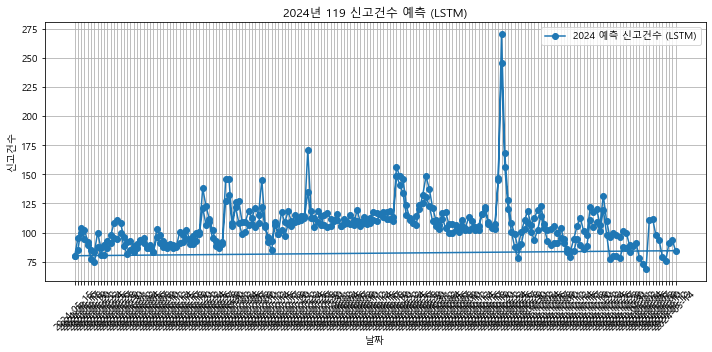

           날짜  예측 신고건수
0  2024-05-15       79
1  2024-05-16       95
2  2024-05-17       99
3  2024-05-18      102
4  2024-05-19       91


In [10]:
import numpy as np
import matplotlib.pyplot as plt

# 2024년 날씨 데이터 불러오기
weather_2024 = pd.read_csv('24년 부산_기상청자료.csv', encoding='cp949')

# 특성 선택
features = ['평균기온(°C)', '최저기온(°C)', '최고기온(°C)', '일강수량(mm)',
            '최대 순간 풍속(m/s)', '최대 풍속(m/s)', '평균 이슬점온도(°C)', '최소 상대습도(%)']
X_2024 = weather_2024[features]

# 결측치 처리 (예: 0으로 대체)
X_2024 = X_2024.fillna(0)

# 스케일링 (train 때 사용한 scaler_X 사용)
X_2024_scaled = scaler_X.transform(X_2024)

# 시퀀스 생성 (LSTM과 동일한 seq_length 사용)
X_2024_seq = []
for i in range(len(X_2024_scaled) - seq_length):
    X_2024_seq.append(X_2024_scaled[i:i+seq_length])
X_2024_seq = np.array(X_2024_seq)

# 예측
y_2024_scaled = model_lstm.predict(X_2024_seq)
y_2024 = scaler_y.inverse_transform(y_2024_scaled)

# 날짜 추출 (시퀀스 길이 이후부터 예측 가능)
predict_dates = weather_2024['일시'].values[seq_length:]

# 결과 시각화
plt.figure(figsize=(10,5))
plt.plot(predict_dates, y_2024, label='2024 예측 신고건수 (LSTM)', marker='o')
plt.xticks(rotation=45)
plt.title("2024년 119 신고건수 예측 (LSTM)")
plt.xlabel("날짜")
plt.ylabel("신고건수")
plt.grid()
plt.legend()
plt.tight_layout()
plt.show()

# 결과 DataFrame 생성
result_df_lstm = pd.DataFrame({
    '날짜': predict_dates,
    '예측 신고건수': y_2024.flatten().astype(int)
})

print(result_df_lstm.head())


12/12 [==============================] - 0s 2ms/step


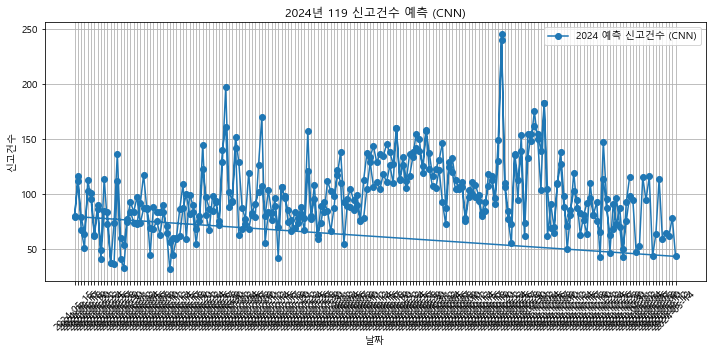

           날짜  예측 신고건수
0  2024-05-15       79
1  2024-05-16      111
2  2024-05-17       78
3  2024-05-18       63
4  2024-05-19      102


In [11]:
# CNN 모델 사용 시 동일한 전처리 과정

# 스케일링 및 시퀀스 생성은 위 LSTM 코드와 동일하므로 재사용

# 예측
y_2024_scaled_cnn = model_cnn.predict(X_2024_seq)
y_2024_cnn = scaler_y.inverse_transform(y_2024_scaled_cnn)

# 결과 시각화
plt.figure(figsize=(10,5))
plt.plot(predict_dates, y_2024_cnn, label='2024 예측 신고건수 (CNN)', marker='o')
plt.xticks(rotation=45)
plt.title("2024년 119 신고건수 예측 (CNN)")
plt.xlabel("날짜")
plt.ylabel("신고건수")
plt.grid()
plt.legend()
plt.tight_layout()
plt.show()

# 결과 DataFrame 생성
result_df_cnn = pd.DataFrame({
    '날짜': predict_dates,
    '예측 신고건수': y_2024_cnn.flatten().astype(int)
})

print(result_df_cnn.head())
